# 06 — Verdieping: het ratio-model

Deze notebook hoort bij [`docs/methodologie/ratio-model.md`](../docs/methodologie/ratio-model.md).
Het ratio-model is de **simpelste** voorspeller in het cumulatieve spoor: volledig
transparant, altijd beschikbaar, en daarom de baseline.

$$
\bar{R}_t = \frac{1}{3} \sum_{j=1}^{3} \frac{\text{Aanmelding}_{jaar-j,\, week=t}}{\text{Aantal studenten}_{jaar-j}}
\quad\Rightarrow\quad
\hat{y} = \frac{\text{Aanmelding}_{huidig,\, week=t}}{\bar{R}_t}
$$

Met `Aanmelding = Ongewogen vooraanmelders + Inschrijvingen` en een venster van 3 jaar
(`LOOKBACK_YEARS`).

Het [CWF-model](02_cwf_model.ipynb) bouwt op hetzelfde idee voort, maar weegt recente
jaren zwaarder, combineert met een prior en geeft een interval.


> 🧭 **Verdieping: een ander spoor.** Het aanbevolen model is het
> [CWF-model](02_cwf_model.ipynb): het is doorgaans nauwkeuriger en
> geeft er een onzekerheidsmarge en betrouwbaarheidslabel bij. Deze notebook legt
> een van de andere sporen uit. Die zijn nog steeds te gebruiken (`-d c`, `-d i`,
> `-d b`), bijvoorbeeld om te vergelijken.


> ℹ️ **Over de demodata.** De notebooks draaien op de meegeleverde, synthetische
> demodata in `data/input/`. Daarin staan de aanmeldingen van alle instellingen
> per opleiding opgeteld, net zoals de pipeline dat doet zonder `institution_filter`.
> Opleidingen zijn **Isatcodes** (bijv. `56604` = B Psychologie); waar het helpt
> staat de naam erachter.
>
> Twee eigenaardigheden van de demodata: **inschrijvingen zijn altijd 0** en
> **de aanmelders zakken vanaf eind mei (rond week 23) kunstmatig in**. Daarom
> gebruiken de notebooks een vroege peilweek (12). Op echte telbestanden speelt dit niet.
>
> **Met eigen data:** vervang de bestanden in `data/input/` en pas `PROGRAMMA`,
> `PREDICT_YEAR` en `PREDICT_WEEK` aan.


In [1]:
# --- Standaard setup voor alle studentprognose-notebooks ---
import sys
from pathlib import Path

# Maak _helpers.py importeerbaar en ga naar projectroot
NOTEBOOKS_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOKS_DIR))

from _helpers import project_root, setup_matplotlib  # noqa: E402
project_root()
setup_matplotlib()

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("Projectmap gevonden:", "ja" if Path("data/input").is_dir() else "nee — start Jupyter vanuit de repo")
print("Python:", sys.version.split()[0])


Projectmap gevonden: ja
Python: 3.12.12


In [2]:
from _helpers import load_cumulative, opleidingsnamen, label

data_cumulative, data_studentcount, data_cumulative_raw = load_cumulative()
NAMEN = opleidingsnamen()
print(f"Telregels (opgeteld over instellingen): {len(data_cumulative):,}")
print(f"Aantal opleidingen:                     {data_cumulative['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:                           {data_cumulative['Collegejaar'].min()}–{data_cumulative['Collegejaar'].max()}")
print(f"Realisatie (studentaantallen):          {len(data_studentcount):,} rijen")


Telregels (opgeteld over instellingen): 64,947
Aantal opleidingen:                     393
Collegejaren:                           2020–2026
Realisatie (studentaantallen):          2,934 rijen


## 1. Ratio stap voor stap, voorspelling voor 2023


In [3]:
PROGRAMMA = 56604  # B Psychologie
HERKOMST = "NL"
EXAMENTYPE = "Bachelor"
PREDICT_YEAR = 2023
PREDICT_WEEK = 12
LOOKBACK = 3

combo = data_cumulative[
    (data_cumulative["Croho groepeernaam"] == PROGRAMMA)
    & (data_cumulative["Herkomst"] == HERKOMST)
    & (data_cumulative["Examentype"] == EXAMENTYPE)
].copy()
combo["Aanmelding"] = combo["Ongewogen vooraanmelders"].fillna(0) + combo["Inschrijvingen"].fillna(0)
combo = combo.merge(data_studentcount, on=["Collegejaar", "Croho groepeernaam", "Herkomst", "Examentype"], how="left")
combo["Ratio"] = combo["Aanmelding"] / combo["Aantal_studenten"]


def ratio_prognose(jaar: int, week: int = PREDICT_WEEK):
    hist = combo[(combo["Weeknummer"] == week) & combo["Collegejaar"].between(jaar - LOOKBACK, jaar - 1)]
    nu = combo[(combo["Weeknummer"] == week) & (combo["Collegejaar"] == jaar)]
    gem_ratio = hist["Ratio"].mean()
    if hist.empty or nu.empty or not np.isfinite(gem_ratio) or gem_ratio == 0:
        return np.nan, hist
    return float(nu["Aanmelding"].sum() / gem_ratio), hist


prognose, hist = ratio_prognose(PREDICT_YEAR)
werkelijk = float(combo.loc[combo["Collegejaar"] == PREDICT_YEAR, "Aantal_studenten"].dropna().iloc[0])
print(f"{label(PROGRAMMA, NAMEN)} · {HERKOMST} · peilweek {PREDICT_WEEK}")
print(hist[["Collegejaar", "Aanmelding", "Aantal_studenten", "Ratio"]].round(3).to_string(index=False))
print(f"Gemiddelde ratio: {hist['Ratio'].mean():.3f}")
print(f"Prognose {PREDICT_YEAR}: {prognose:.0f} · realisatie: {werkelijk:.0f} · fout: {(prognose - werkelijk) / werkelijk:+.1%}")


56604 B Psychologie · NL · peilweek 12
 Collegejaar  Aanmelding  Aantal_studenten  Ratio
        2020      1904.0             272.0  7.000
        2021      2084.0             238.0  8.756
        2022      1471.0             229.0  6.424
Gemiddelde ratio: 7.393
Prognose 2023: 268 · realisatie: 253 · fout: +6.1%


## 2. Backtest over meerdere jaren

Eén jaar zegt weinig. We voorspellen elk jaar waarvoor drie eerdere jaren bestaan.


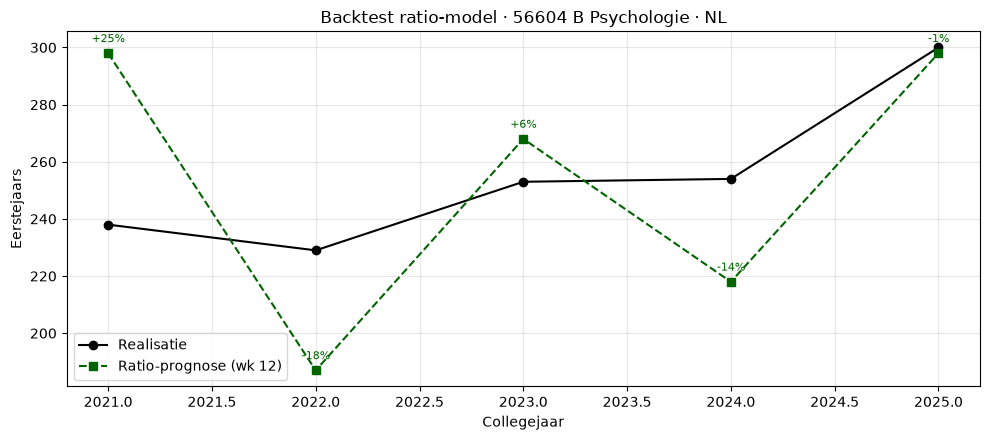

,jaar,prognose,realisatie,fout_%
0,2021,298,238,25.1
1,2022,187,229,-18.5
2,2023,268,253,6.1
3,2024,218,254,-14.2
4,2025,298,300,-0.8


In [4]:
records = []
for jaar in sorted(combo["Collegejaar"].unique()):
    p, _ = ratio_prognose(int(jaar))
    r = combo.loc[combo["Collegejaar"] == jaar, "Aantal_studenten"].dropna()
    if np.isfinite(p) and len(r):
        r = float(r.iloc[0])
        records.append({"jaar": int(jaar), "prognose": round(p), "realisatie": int(r),
                        "fout_%": round((p - r) / r * 100, 1)})
backtest = pd.DataFrame(records)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(backtest["jaar"], backtest["realisatie"], "o-", color="black", label="Realisatie")
ax.plot(backtest["jaar"], backtest["prognose"], "s--", color="darkgreen", label=f"Ratio-prognose (wk {PREDICT_WEEK})")
for _, r in backtest.iterrows():
    ax.annotate(f"{r['fout_%']:+.0f}%", (r["jaar"], r["prognose"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8, color="darkgreen")
ax.set_xlabel("Collegejaar")
ax.set_ylabel("Eerstejaars")
ax.set_title(f"Backtest ratio-model · {label(PROGRAMMA, NAMEN)} · {HERKOMST}")
ax.legend()
plt.tight_layout()
plt.show()
backtest


## 3. Ratio per peilweek: wanneer is hij stabiel?

Vroeg in het jaar is de ratio **onrustig**: een handvol aanmelders meer of minder
slaat hard door. Later in het seizoen wordt hij stabieler.


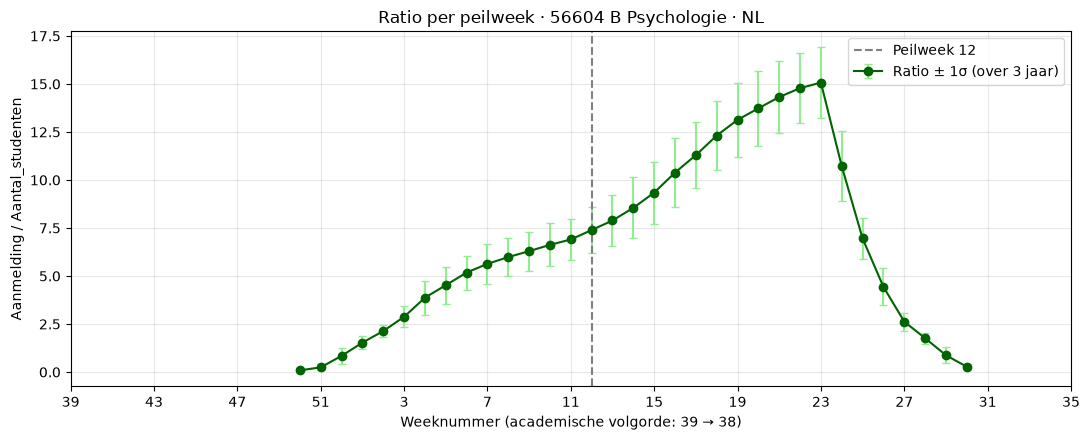

In [5]:
from studentprognose.utils.weeks import get_all_weeks_ordered

volgorde = get_all_weeks_ordered()
vensterjaren = combo[combo["Collegejaar"].between(PREDICT_YEAR - LOOKBACK, PREDICT_YEAR - 1)]
per_week = (
    vensterjaren.replace([np.inf, -np.inf], np.nan)
    .groupby("Weeknummer")["Ratio"].agg(["mean", "std"]).reset_index()
)
per_week["positie"] = per_week["Weeknummer"].astype(str).map({w: i for i, w in enumerate(volgorde)})
per_week = per_week.dropna(subset=["positie"]).sort_values("positie")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.errorbar(per_week["positie"], per_week["mean"], yerr=per_week["std"], fmt="o-",
            color="darkgreen", ecolor="lightgreen", capsize=3, label="Ratio ± 1σ (over 3 jaar)")
ax.axvline(volgorde.index(str(PREDICT_WEEK)), color="gray", linestyle="--", label=f"Peilweek {PREDICT_WEEK}")
ax.set_xticks(range(0, len(volgorde), 4))
ax.set_xticklabels([volgorde[i] for i in range(0, len(volgorde), 4)])
ax.set_xlabel("Weeknummer (academische volgorde: 39 → 38)")
ax.set_ylabel("Aanmelding / Aantal_studenten")
ax.set_title(f"Ratio per peilweek · {label(PROGRAMMA, NAMEN)} · {HERKOMST}")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Numerus fixus: afkappen op de capaciteit

Voor numerus-fixusopleidingen kapt het ratio-model de opgetelde prognose af op de
capaciteit; het overschot gaat van de NL-herkomst af. We laten dat zien op
B Geneeskunde (Isatcode `56551`) met een voorbeeldcapaciteit van 340. In je eigen
configuratie zet je `"numerus_fixus": {"56551": 340}`.


In [6]:
NF_CODE = 56551  # B Geneeskunde
NF_CAPACITEIT = 340

nf = data_cumulative[(data_cumulative["Croho groepeernaam"] == NF_CODE)
                     & (data_cumulative["Examentype"] == "Bachelor")].copy()
nf["Aanmelding"] = nf["Ongewogen vooraanmelders"].fillna(0) + nf["Inschrijvingen"].fillna(0)
nf = nf.merge(data_studentcount, on=["Collegejaar", "Croho groepeernaam", "Herkomst", "Examentype"], how="left")

rijen = []
for herkomst in ["NL", "EER", "Niet-EER"]:
    h = nf[(nf["Herkomst"] == herkomst) & (nf["Weeknummer"] == PREDICT_WEEK)]
    hist_h = h[h["Collegejaar"].between(PREDICT_YEAR - LOOKBACK, PREDICT_YEAR - 1)]
    gem = (hist_h["Aanmelding"] / hist_h["Aantal_studenten"]).replace([np.inf, -np.inf], np.nan).mean()
    nu = h.loc[h["Collegejaar"] == PREDICT_YEAR, "Aanmelding"].sum()
    if np.isfinite(gem) and gem > 0:
        rijen.append({"Herkomst": herkomst, "Ratio-prognose": round(nu / gem)})

nf_df = pd.DataFrame(rijen)
overschot = max(0, nf_df["Ratio-prognose"].sum() - NF_CAPACITEIT)
nf_df["Na afkappen"] = nf_df["Ratio-prognose"]
nf_df.loc[nf_df["Herkomst"] == "NL", "Na afkappen"] = (nf_df.loc[nf_df["Herkomst"] == "NL", "Ratio-prognose"] - overschot).clip(lower=0)

print(f"{label(NF_CODE, NAMEN)} · capaciteit {NF_CAPACITEIT}")
print(f"Totaal vóór afkappen: {nf_df['Ratio-prognose'].sum():.0f} · overschot: {overschot:.0f} (van NL)")
nf_df


56551 B Geneeskunde · capaciteit 340
Totaal vóór afkappen: 348 · overschot: 8 (van NL)


,Herkomst,Ratio-prognose,Na afkappen
0,NL,321,313
1,EER,27,27


## 5. Beperkingen

| Beperking | Waar zie je het? |
|-----------|------------------|
| **Geen trends** | Bij groeiende of krimpende opleidingen lopen de fouten in de backtest op |
| **Gevoelig voor uitschieters** | Eén afwijkend jaar in het venster trekt de gemiddelde ratio mee |
| **Week-afhankelijk** | Vroege weken: brede σ-band in de grafiek hierboven |

Het ratio-model is een **eerlijke baseline**. Het CWF-model pakt de eerste twee
beperkingen aan: recente jaren wegen zwaarder, een geometrisch gemiddelde dempt
uitschieters, en het interval maakt de onzekerheid zichtbaar.
